In [30]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from datasets import concatenate_datasets

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [31]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")
dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})

Map:   0%|          | 0/355 [00:00<?, ? examples/s]

Map:   0%|          | 0/169 [00:00<?, ? examples/s]

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

In [32]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [33]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [34]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [35]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [36]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [37]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [38]:
classifiers = OrderedDict()

In [39]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [40]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [41]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.087 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0296 | train acc: 0.5348 | val loss: 0.9987 | val acc: 0.5063
Epoch 02 | train loss: 0.8944 | train acc: 0.6804 | val loss: 0.9366 | val acc: 0.4937
Epoch 03 | train loss: 0.7788 | train acc: 0.7627 | val loss: 0.8949 | val acc: 0.4937
Epoch 04 | train loss: 0.6964 | train acc: 0.7722 | val loss: 0.8719 | val acc: 0.5063
Epoch 05 | train loss: 0.6138 | train acc: 0.8259 | val loss: 0.8583 | val acc: 0.5316
Epoch 06 | train loss: 0.5396 | train acc: 0.8924 | val loss: 0.8451 | val acc: 0.5570
Epoch 07 | train loss: 0.4650 | train acc: 0.9367 | val loss: 0.8304 | val acc: 0.6203
Epoch 08 | train loss: 0.4013 | train acc: 0.9494 | val loss: 0.8210 | val acc: 0.5823
Epoch 09 | train loss: 0.3426 | train acc: 0.9525 | val loss: 0.8202 | val acc: 0.5949
Epoch 10 | train loss: 0.2912 | train acc: 0.9589 | val loss: 0.8208 | val acc: 0.6076
Epoch 11 | train loss: 0.2385 | train acc: 0.9684 | val loss: 0.8212 | val acc: 0.5696
Epoch 12 | train loss: 0.2025 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0538 | train acc: 0.4304 | val loss: 0.9875 | val acc: 0.5063
Epoch 02 | train loss: 0.9152 | train acc: 0.6962 | val loss: 0.9130 | val acc: 0.5823
Epoch 03 | train loss: 0.8113 | train acc: 0.7943 | val loss: 0.8600 | val acc: 0.6203
Epoch 04 | train loss: 0.7248 | train acc: 0.7880 | val loss: 0.8295 | val acc: 0.5949
Epoch 05 | train loss: 0.6561 | train acc: 0.7943 | val loss: 0.8096 | val acc: 0.6076
Epoch 06 | train loss: 0.5896 | train acc: 0.8513 | val loss: 0.7890 | val acc: 0.6456
Epoch 07 | train loss: 0.5168 | train acc: 0.9304 | val loss: 0.7696 | val acc: 0.6456
Epoch 08 | train loss: 0.4492 | train acc: 0.9430 | val loss: 0.7530 | val acc: 0.6076
Epoch 09 | train loss: 0.3886 | train acc: 0.9494 | val loss: 0.7442 | val acc: 0.6076
Epoch 10 | train loss: 0.3299 | train acc: 0.9462 | val loss: 0.7390 | val acc: 0.5949
Epoch 11 | train loss: 0.2742 | train acc: 0.9589 | val loss: 0.7402 | val acc: 0.5949
Epoch 12 | train loss: 0.2277 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0282 | train acc: 0.5285 | val loss: 0.9598 | val acc: 0.5696
Epoch 02 | train loss: 0.9005 | train acc: 0.5443 | val loss: 0.8808 | val acc: 0.5696
Epoch 03 | train loss: 0.8073 | train acc: 0.5759 | val loss: 0.8286 | val acc: 0.5696
Epoch 04 | train loss: 0.7252 | train acc: 0.6361 | val loss: 0.7981 | val acc: 0.5823
Epoch 05 | train loss: 0.6594 | train acc: 0.7373 | val loss: 0.7764 | val acc: 0.6076
Epoch 06 | train loss: 0.5903 | train acc: 0.8639 | val loss: 0.7599 | val acc: 0.6835
Epoch 07 | train loss: 0.5221 | train acc: 0.9241 | val loss: 0.7440 | val acc: 0.6582
Epoch 08 | train loss: 0.4544 | train acc: 0.9304 | val loss: 0.7286 | val acc: 0.6582
Epoch 09 | train loss: 0.3935 | train acc: 0.9430 | val loss: 0.7167 | val acc: 0.6835
Epoch 10 | train loss: 0.3364 | train acc: 0.9525 | val loss: 0.7044 | val acc: 0.7215
Epoch 11 | train loss: 0.2821 | train acc: 0.9557 | val loss: 0.6964 | val acc: 0.7089
Epoch 12 | train loss: 0.2375 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0648 | train acc: 0.4304 | val loss: 0.9768 | val acc: 0.5443
Epoch 02 | train loss: 0.9265 | train acc: 0.6329 | val loss: 0.8928 | val acc: 0.5570
Epoch 03 | train loss: 0.8264 | train acc: 0.6614 | val loss: 0.8264 | val acc: 0.5316
Epoch 04 | train loss: 0.7365 | train acc: 0.6962 | val loss: 0.7768 | val acc: 0.5570
Epoch 05 | train loss: 0.6612 | train acc: 0.7785 | val loss: 0.7404 | val acc: 0.6076
Epoch 06 | train loss: 0.5864 | train acc: 0.8418 | val loss: 0.7119 | val acc: 0.5823
Epoch 07 | train loss: 0.5192 | train acc: 0.9209 | val loss: 0.6869 | val acc: 0.6076
Epoch 08 | train loss: 0.4468 | train acc: 0.9399 | val loss: 0.6727 | val acc: 0.6203
Epoch 09 | train loss: 0.3837 | train acc: 0.9462 | val loss: 0.6626 | val acc: 0.6203
Epoch 10 | train loss: 0.3196 | train acc: 0.9525 | val loss: 0.6581 | val acc: 0.6076
Epoch 11 | train loss: 0.2671 | train acc: 0.9557 | val loss: 0.6589 | val acc: 0.6076
Epoch 12 | train loss: 0.2253 | train acc: 

In [42]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.077 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0976 | train acc: 0.3133 | val loss: 1.0509 | val acc: 0.5190
Epoch 02 | train loss: 0.9801 | train acc: 0.7215 | val loss: 0.9659 | val acc: 0.5823
Epoch 03 | train loss: 0.8559 | train acc: 0.7373 | val loss: 0.8989 | val acc: 0.5190
Epoch 04 | train loss: 0.7517 | train acc: 0.6392 | val loss: 0.8875 | val acc: 0.5063
Epoch 05 | train loss: 0.6705 | train acc: 0.7342 | val loss: 0.8913 | val acc: 0.5696
Epoch 06 | train loss: 0.5675 | train acc: 0.8671 | val loss: 0.8856 | val acc: 0.5949
Epoch 07 | train loss: 0.4548 | train acc: 0.9272 | val loss: 0.8672 | val acc: 0.6203
Epoch 08 | train loss: 0.3254 | train acc: 0.9494 | val loss: 0.8773 | val acc: 0.5696
Epoch 09 | train loss: 0.2236 | train acc: 0.9557 | val loss: 0.8849 | val acc: 0.6203
Epoch 10 | train loss: 0.1500 | train acc: 0.9620 | val loss: 0.9151 | val acc: 0.6203
Epoch 11 | train loss: 0.1012 | train acc: 0.9684 | val loss: 0.9849 | val acc: 0.6456
Epoch 12 | train loss: 0.0719 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0615 | train acc: 0.4525 | val loss: 1.0062 | val acc: 0.5443
Epoch 02 | train loss: 0.9394 | train acc: 0.6582 | val loss: 0.9143 | val acc: 0.5570
Epoch 03 | train loss: 0.8257 | train acc: 0.5696 | val loss: 0.8546 | val acc: 0.5316
Epoch 04 | train loss: 0.7337 | train acc: 0.5601 | val loss: 0.8342 | val acc: 0.5696
Epoch 05 | train loss: 0.6553 | train acc: 0.7025 | val loss: 0.8095 | val acc: 0.6582
Epoch 06 | train loss: 0.5560 | train acc: 0.8892 | val loss: 0.7888 | val acc: 0.6582
Epoch 07 | train loss: 0.4388 | train acc: 0.9272 | val loss: 0.7652 | val acc: 0.6203
Epoch 08 | train loss: 0.3183 | train acc: 0.9399 | val loss: 0.7753 | val acc: 0.6329
Epoch 09 | train loss: 0.2223 | train acc: 0.9525 | val loss: 0.7922 | val acc: 0.5949
Epoch 10 | train loss: 0.1483 | train acc: 0.9620 | val loss: 0.8194 | val acc: 0.5823
Epoch 11 | train loss: 0.1092 | train acc: 0.9652 | val loss: 0.8707 | val acc: 0.5949
Epoch 12 | train loss: 0.0824 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0349 | train acc: 0.5095 | val loss: 0.9777 | val acc: 0.5823
Epoch 02 | train loss: 0.9418 | train acc: 0.5601 | val loss: 0.8973 | val acc: 0.5823
Epoch 03 | train loss: 0.8525 | train acc: 0.5696 | val loss: 0.8245 | val acc: 0.5696
Epoch 04 | train loss: 0.7648 | train acc: 0.6456 | val loss: 0.7849 | val acc: 0.5823
Epoch 05 | train loss: 0.6847 | train acc: 0.7532 | val loss: 0.7681 | val acc: 0.6203
Epoch 06 | train loss: 0.5916 | train acc: 0.8671 | val loss: 0.7492 | val acc: 0.6709
Epoch 07 | train loss: 0.4723 | train acc: 0.9335 | val loss: 0.7273 | val acc: 0.6582
Epoch 08 | train loss: 0.3506 | train acc: 0.9367 | val loss: 0.7065 | val acc: 0.6582
Epoch 09 | train loss: 0.2409 | train acc: 0.9589 | val loss: 0.7021 | val acc: 0.6835
Epoch 10 | train loss: 0.1643 | train acc: 0.9589 | val loss: 0.7183 | val acc: 0.6709
Epoch 11 | train loss: 0.1133 | train acc: 0.9589 | val loss: 0.7572 | val acc: 0.6709
Epoch 12 | train loss: 0.0859 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0934 | train acc: 0.3544 | val loss: 1.0303 | val acc: 0.5570
Epoch 02 | train loss: 0.9810 | train acc: 0.6329 | val loss: 0.9168 | val acc: 0.5063
Epoch 03 | train loss: 0.8648 | train acc: 0.5475 | val loss: 0.8082 | val acc: 0.5063
Epoch 04 | train loss: 0.7540 | train acc: 0.5506 | val loss: 0.7340 | val acc: 0.5063
Epoch 05 | train loss: 0.6721 | train acc: 0.6835 | val loss: 0.6701 | val acc: 0.5443
Epoch 06 | train loss: 0.5627 | train acc: 0.8987 | val loss: 0.6392 | val acc: 0.6456
Epoch 07 | train loss: 0.4443 | train acc: 0.9209 | val loss: 0.6283 | val acc: 0.6456
Epoch 08 | train loss: 0.3226 | train acc: 0.9367 | val loss: 0.6236 | val acc: 0.6329
Epoch 09 | train loss: 0.2263 | train acc: 0.9399 | val loss: 0.6435 | val acc: 0.6709
Epoch 10 | train loss: 0.1535 | train acc: 0.9462 | val loss: 0.7037 | val acc: 0.6456
Epoch 11 | train loss: 0.1103 | train acc: 0.9525 | val loss: 0.7636 | val acc: 0.6456
Epoch 12 | train loss: 0.0827 | train acc: 

In [43]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [44]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.090 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0547 | train acc: 0.5000 | val loss: 1.0076 | val acc: 0.5316
Epoch 02 | train loss: 0.9020 | train acc: 0.6266 | val loss: 0.9394 | val acc: 0.5063
Epoch 03 | train loss: 0.7918 | train acc: 0.6551 | val loss: 0.8943 | val acc: 0.5190
Epoch 04 | train loss: 0.6991 | train acc: 0.7500 | val loss: 0.8677 | val acc: 0.5443
Epoch 05 | train loss: 0.6160 | train acc: 0.8101 | val loss: 0.8494 | val acc: 0.5696
Epoch 06 | train loss: 0.5450 | train acc: 0.8861 | val loss: 0.8316 | val acc: 0.6329
Epoch 07 | train loss: 0.4774 | train acc: 0.9272 | val loss: 0.8169 | val acc: 0.6329
Epoch 08 | train loss: 0.4135 | train acc: 0.9367 | val loss: 0.8041 | val acc: 0.6329
Epoch 09 | train loss: 0.3536 | train acc: 0.9494 | val loss: 0.7925 | val acc: 0.6203
Epoch 10 | train loss: 0.2953 | train acc: 0.9620 | val loss: 0.7889 | val acc: 0.6203
Epoch 11 | train loss: 0.2528 | train acc: 0.9620 | val loss: 0.7851 | val acc: 0.6329
Epoch 12 | train loss: 0.2100 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0943 | train acc: 0.3671 | val loss: 1.0004 | val acc: 0.5570
Epoch 02 | train loss: 0.9320 | train acc: 0.5759 | val loss: 0.9153 | val acc: 0.5443
Epoch 03 | train loss: 0.8165 | train acc: 0.6076 | val loss: 0.8616 | val acc: 0.5443
Epoch 04 | train loss: 0.7266 | train acc: 0.6804 | val loss: 0.8271 | val acc: 0.5570
Epoch 05 | train loss: 0.6521 | train acc: 0.7816 | val loss: 0.7997 | val acc: 0.5949
Epoch 06 | train loss: 0.5794 | train acc: 0.9082 | val loss: 0.7769 | val acc: 0.5949
Epoch 07 | train loss: 0.5100 | train acc: 0.9430 | val loss: 0.7577 | val acc: 0.6329
Epoch 08 | train loss: 0.4450 | train acc: 0.9367 | val loss: 0.7413 | val acc: 0.6456
Epoch 09 | train loss: 0.3776 | train acc: 0.9462 | val loss: 0.7319 | val acc: 0.6329
Epoch 10 | train loss: 0.3178 | train acc: 0.9589 | val loss: 0.7237 | val acc: 0.6203
Epoch 11 | train loss: 0.2631 | train acc: 0.9589 | val loss: 0.7184 | val acc: 0.6203
Epoch 12 | train loss: 0.2207 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1100 | train acc: 0.2816 | val loss: 1.0221 | val acc: 0.5823
Epoch 02 | train loss: 0.9461 | train acc: 0.6456 | val loss: 0.9197 | val acc: 0.5823
Epoch 03 | train loss: 0.8336 | train acc: 0.7563 | val loss: 0.8501 | val acc: 0.6203
Epoch 04 | train loss: 0.7445 | train acc: 0.7943 | val loss: 0.8048 | val acc: 0.5823
Epoch 05 | train loss: 0.6663 | train acc: 0.8354 | val loss: 0.7784 | val acc: 0.5823
Epoch 06 | train loss: 0.5952 | train acc: 0.8734 | val loss: 0.7594 | val acc: 0.6203
Epoch 07 | train loss: 0.5295 | train acc: 0.9146 | val loss: 0.7439 | val acc: 0.6835
Epoch 08 | train loss: 0.4650 | train acc: 0.9272 | val loss: 0.7276 | val acc: 0.6709
Epoch 09 | train loss: 0.3978 | train acc: 0.9525 | val loss: 0.7145 | val acc: 0.6835
Epoch 10 | train loss: 0.3426 | train acc: 0.9525 | val loss: 0.7027 | val acc: 0.6835
Epoch 11 | train loss: 0.2894 | train acc: 0.9589 | val loss: 0.6964 | val acc: 0.6835
Epoch 12 | train loss: 0.2428 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0734 | train acc: 0.4177 | val loss: 0.9947 | val acc: 0.5190
Epoch 02 | train loss: 0.9134 | train acc: 0.5918 | val loss: 0.8965 | val acc: 0.5190
Epoch 03 | train loss: 0.8115 | train acc: 0.6108 | val loss: 0.8246 | val acc: 0.5190
Epoch 04 | train loss: 0.7255 | train acc: 0.6551 | val loss: 0.7783 | val acc: 0.5443
Epoch 05 | train loss: 0.6524 | train acc: 0.7627 | val loss: 0.7381 | val acc: 0.5316
Epoch 06 | train loss: 0.5764 | train acc: 0.8829 | val loss: 0.7069 | val acc: 0.6203
Epoch 07 | train loss: 0.5094 | train acc: 0.9209 | val loss: 0.6872 | val acc: 0.6456
Epoch 08 | train loss: 0.4398 | train acc: 0.9399 | val loss: 0.6746 | val acc: 0.6709
Epoch 09 | train loss: 0.3741 | train acc: 0.9525 | val loss: 0.6694 | val acc: 0.6582
Epoch 10 | train loss: 0.3164 | train acc: 0.9557 | val loss: 0.6670 | val acc: 0.6456
Epoch 11 | train loss: 0.2656 | train acc: 0.9589 | val loss: 0.6741 | val acc: 0.6456
Epoch 12 | train loss: 0.2163 | train acc: 

In [45]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.104 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0429 | train acc: 0.4367 | val loss: 0.9927 | val acc: 0.4937
Epoch 02 | train loss: 0.9184 | train acc: 0.5823 | val loss: 0.9146 | val acc: 0.4937
Epoch 03 | train loss: 0.8088 | train acc: 0.5665 | val loss: 0.8792 | val acc: 0.5063
Epoch 04 | train loss: 0.7280 | train acc: 0.6076 | val loss: 0.8803 | val acc: 0.5063
Epoch 05 | train loss: 0.6565 | train acc: 0.7816 | val loss: 0.8711 | val acc: 0.6203
Epoch 06 | train loss: 0.5470 | train acc: 0.8861 | val loss: 0.8472 | val acc: 0.6456
Epoch 07 | train loss: 0.4244 | train acc: 0.9241 | val loss: 0.8229 | val acc: 0.6709
Epoch 08 | train loss: 0.3122 | train acc: 0.9430 | val loss: 0.8118 | val acc: 0.6709
Epoch 09 | train loss: 0.2097 | train acc: 0.9589 | val loss: 0.8245 | val acc: 0.6709
Epoch 10 | train loss: 0.1361 | train acc: 0.9652 | val loss: 0.8623 | val acc: 0.6709
Epoch 11 | train loss: 0.0994 | train acc: 0.9715 | val loss: 0.9091 | val acc: 0.6709
Epoch 12 | train loss: 0.0702 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0561 | train acc: 0.4462 | val loss: 1.0032 | val acc: 0.5063
Epoch 02 | train loss: 0.9425 | train acc: 0.5854 | val loss: 0.9206 | val acc: 0.5443
Epoch 03 | train loss: 0.8362 | train acc: 0.5506 | val loss: 0.8654 | val acc: 0.5316
Epoch 04 | train loss: 0.7489 | train acc: 0.5601 | val loss: 0.8417 | val acc: 0.5443
Epoch 05 | train loss: 0.6667 | train acc: 0.7215 | val loss: 0.8339 | val acc: 0.6203
Epoch 06 | train loss: 0.5688 | train acc: 0.9177 | val loss: 0.8220 | val acc: 0.6203
Epoch 07 | train loss: 0.4501 | train acc: 0.9177 | val loss: 0.8169 | val acc: 0.6329
Epoch 08 | train loss: 0.3187 | train acc: 0.9494 | val loss: 0.8398 | val acc: 0.6203
Epoch 09 | train loss: 0.2272 | train acc: 0.9525 | val loss: 0.8632 | val acc: 0.6076
Epoch 10 | train loss: 0.1502 | train acc: 0.9620 | val loss: 0.9329 | val acc: 0.6076
Epoch 11 | train loss: 0.1076 | train acc: 0.9652 | val loss: 1.0149 | val acc: 0.6076
Epoch 12 | train loss: 0.0783 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0821 | train acc: 0.3671 | val loss: 1.0160 | val acc: 0.5949
Epoch 02 | train loss: 0.9644 | train acc: 0.6804 | val loss: 0.9053 | val acc: 0.6203
Epoch 03 | train loss: 0.8479 | train acc: 0.5949 | val loss: 0.8181 | val acc: 0.5823
Epoch 04 | train loss: 0.7659 | train acc: 0.5506 | val loss: 0.7893 | val acc: 0.5696
Epoch 05 | train loss: 0.6903 | train acc: 0.6804 | val loss: 0.7781 | val acc: 0.6582
Epoch 06 | train loss: 0.6109 | train acc: 0.8829 | val loss: 0.7575 | val acc: 0.6582
Epoch 07 | train loss: 0.5071 | train acc: 0.8956 | val loss: 0.7316 | val acc: 0.7089
Epoch 08 | train loss: 0.3842 | train acc: 0.9209 | val loss: 0.6983 | val acc: 0.7089
Epoch 09 | train loss: 0.2788 | train acc: 0.9399 | val loss: 0.6953 | val acc: 0.6962
Epoch 10 | train loss: 0.1963 | train acc: 0.9525 | val loss: 0.7176 | val acc: 0.6962
Epoch 11 | train loss: 0.1350 | train acc: 0.9684 | val loss: 0.7171 | val acc: 0.6835
Epoch 12 | train loss: 0.0964 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0243 | train acc: 0.5411 | val loss: 0.9489 | val acc: 0.4937
Epoch 02 | train loss: 0.9162 | train acc: 0.5570 | val loss: 0.8527 | val acc: 0.5063
Epoch 03 | train loss: 0.8230 | train acc: 0.5443 | val loss: 0.7794 | val acc: 0.5063
Epoch 04 | train loss: 0.7534 | train acc: 0.5570 | val loss: 0.7263 | val acc: 0.5190
Epoch 05 | train loss: 0.6733 | train acc: 0.7184 | val loss: 0.6850 | val acc: 0.5570
Epoch 06 | train loss: 0.5690 | train acc: 0.8861 | val loss: 0.6610 | val acc: 0.6203
Epoch 07 | train loss: 0.4441 | train acc: 0.9019 | val loss: 0.6525 | val acc: 0.5949
Epoch 08 | train loss: 0.3160 | train acc: 0.9304 | val loss: 0.6560 | val acc: 0.6329
Epoch 09 | train loss: 0.2189 | train acc: 0.9367 | val loss: 0.7029 | val acc: 0.6329
Epoch 10 | train loss: 0.1504 | train acc: 0.9494 | val loss: 0.7754 | val acc: 0.6329
Epoch 11 | train loss: 0.1080 | train acc: 0.9525 | val loss: 0.8517 | val acc: 0.6203
Epoch 12 | train loss: 0.0795 | train acc: 

In [46]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [47]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.137 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0624 | train acc: 0.4241 | val loss: 1.0550 | val acc: 0.4177
Epoch 02 | train loss: 1.0357 | train acc: 0.4873 | val loss: 1.0356 | val acc: 0.4557
Epoch 03 | train loss: 1.0080 | train acc: 0.7342 | val loss: 1.0133 | val acc: 0.5570
Epoch 04 | train loss: 0.9744 | train acc: 0.8544 | val loss: 0.9882 | val acc: 0.5570
Epoch 05 | train loss: 0.9364 | train acc: 0.7943 | val loss: 0.9615 | val acc: 0.5316
Epoch 06 | train loss: 0.8967 | train acc: 0.7373 | val loss: 0.9344 | val acc: 0.5063
Epoch 07 | train loss: 0.8547 | train acc: 0.6646 | val loss: 0.9091 | val acc: 0.5063
Epoch 08 | train loss: 0.8116 | train acc: 0.6677 | val loss: 0.8868 | val acc: 0.5063
Epoch 09 | train loss: 0.7716 | train acc: 0.6614 | val loss: 0.8682 | val acc: 0.5063
Epoch 10 | train loss: 0.7362 | train acc: 0.6741 | val loss: 0.8538 | val acc: 0.5190
Epoch 11 | train loss: 0.6959 | train acc: 0.7342 | val loss: 0.8411 | val acc: 0.5443
Epoch 12 | train loss: 0.6574 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1068 | train acc: 0.4272 | val loss: 1.0950 | val acc: 0.4177
Epoch 02 | train loss: 1.0766 | train acc: 0.4272 | val loss: 1.0691 | val acc: 0.4177
Epoch 03 | train loss: 1.0420 | train acc: 0.4272 | val loss: 1.0389 | val acc: 0.4177
Epoch 04 | train loss: 1.0042 | train acc: 0.4684 | val loss: 1.0049 | val acc: 0.4430
Epoch 05 | train loss: 0.9603 | train acc: 0.6646 | val loss: 0.9691 | val acc: 0.5443
Epoch 06 | train loss: 0.9168 | train acc: 0.8924 | val loss: 0.9336 | val acc: 0.5696
Epoch 07 | train loss: 0.8688 | train acc: 0.9177 | val loss: 0.9012 | val acc: 0.6076
Epoch 08 | train loss: 0.8261 | train acc: 0.8513 | val loss: 0.8729 | val acc: 0.6076
Epoch 09 | train loss: 0.7844 | train acc: 0.8133 | val loss: 0.8497 | val acc: 0.6076
Epoch 10 | train loss: 0.7442 | train acc: 0.7785 | val loss: 0.8312 | val acc: 0.6076
Epoch 11 | train loss: 0.7115 | train acc: 0.7753 | val loss: 0.8164 | val acc: 0.6076
Epoch 12 | train loss: 0.6769 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0774 | train acc: 0.5158 | val loss: 1.0634 | val acc: 0.5443
Epoch 02 | train loss: 1.0525 | train acc: 0.6013 | val loss: 1.0418 | val acc: 0.5696
Epoch 03 | train loss: 1.0266 | train acc: 0.6392 | val loss: 1.0162 | val acc: 0.5823
Epoch 04 | train loss: 0.9962 | train acc: 0.6962 | val loss: 0.9862 | val acc: 0.5949
Epoch 05 | train loss: 0.9603 | train acc: 0.7310 | val loss: 0.9527 | val acc: 0.5823
Epoch 06 | train loss: 0.9217 | train acc: 0.7658 | val loss: 0.9176 | val acc: 0.5823
Epoch 07 | train loss: 0.8783 | train acc: 0.7753 | val loss: 0.8828 | val acc: 0.5823
Epoch 08 | train loss: 0.8368 | train acc: 0.7595 | val loss: 0.8496 | val acc: 0.5823
Epoch 09 | train loss: 0.7959 | train acc: 0.7690 | val loss: 0.8213 | val acc: 0.5823
Epoch 10 | train loss: 0.7548 | train acc: 0.8101 | val loss: 0.7962 | val acc: 0.5823
Epoch 11 | train loss: 0.7195 | train acc: 0.8038 | val loss: 0.7751 | val acc: 0.5696
Epoch 12 | train loss: 0.6774 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1077 | train acc: 0.0981 | val loss: 1.0951 | val acc: 0.5190
Epoch 02 | train loss: 1.0814 | train acc: 0.6361 | val loss: 1.0725 | val acc: 0.5316
Epoch 03 | train loss: 1.0540 | train acc: 0.6835 | val loss: 1.0451 | val acc: 0.5316
Epoch 04 | train loss: 1.0227 | train acc: 0.6741 | val loss: 1.0121 | val acc: 0.5316
Epoch 05 | train loss: 0.9846 | train acc: 0.7057 | val loss: 0.9754 | val acc: 0.5316
Epoch 06 | train loss: 0.9432 | train acc: 0.6962 | val loss: 0.9360 | val acc: 0.5190
Epoch 07 | train loss: 0.8982 | train acc: 0.7057 | val loss: 0.8968 | val acc: 0.5316
Epoch 08 | train loss: 0.8527 | train acc: 0.6867 | val loss: 0.8594 | val acc: 0.5316
Epoch 09 | train loss: 0.8093 | train acc: 0.6962 | val loss: 0.8259 | val acc: 0.5316
Epoch 10 | train loss: 0.7663 | train acc: 0.7152 | val loss: 0.7962 | val acc: 0.5190
Epoch 11 | train loss: 0.7256 | train acc: 0.7532 | val loss: 0.7710 | val acc: 0.5443
Epoch 12 | train loss: 0.6860 | train acc: 

In [48]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.137 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0394 | train acc: 0.4557 | val loss: 0.9981 | val acc: 0.4937
Epoch 02 | train loss: 0.9200 | train acc: 0.6361 | val loss: 0.9197 | val acc: 0.5063
Epoch 03 | train loss: 0.8136 | train acc: 0.5570 | val loss: 0.8843 | val acc: 0.5063
Epoch 04 | train loss: 0.7364 | train acc: 0.5633 | val loss: 0.8921 | val acc: 0.5063
Epoch 05 | train loss: 0.6568 | train acc: 0.7563 | val loss: 0.8862 | val acc: 0.5696
Epoch 06 | train loss: 0.5553 | train acc: 0.8829 | val loss: 0.8722 | val acc: 0.5823
Epoch 07 | train loss: 0.4396 | train acc: 0.9177 | val loss: 0.8530 | val acc: 0.6203
Epoch 08 | train loss: 0.3189 | train acc: 0.9399 | val loss: 0.8428 | val acc: 0.6329
Epoch 09 | train loss: 0.2141 | train acc: 0.9557 | val loss: 0.8619 | val acc: 0.6582
Epoch 10 | train loss: 0.1473 | train acc: 0.9652 | val loss: 0.8999 | val acc: 0.6582
Epoch 11 | train loss: 0.0988 | train acc: 0.9652 | val loss: 0.9431 | val acc: 0.6329
Epoch 12 | train loss: 0.0748 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0845 | train acc: 0.3924 | val loss: 1.0141 | val acc: 0.5570
Epoch 02 | train loss: 0.9515 | train acc: 0.5538 | val loss: 0.9169 | val acc: 0.5316
Epoch 03 | train loss: 0.8394 | train acc: 0.5380 | val loss: 0.8678 | val acc: 0.5316
Epoch 04 | train loss: 0.7595 | train acc: 0.5380 | val loss: 0.8433 | val acc: 0.5316
Epoch 05 | train loss: 0.6817 | train acc: 0.6741 | val loss: 0.8136 | val acc: 0.6329
Epoch 06 | train loss: 0.5963 | train acc: 0.9114 | val loss: 0.7954 | val acc: 0.6456
Epoch 07 | train loss: 0.4898 | train acc: 0.9114 | val loss: 0.7961 | val acc: 0.6709
Epoch 08 | train loss: 0.3716 | train acc: 0.9177 | val loss: 0.7863 | val acc: 0.5823
Epoch 09 | train loss: 0.2711 | train acc: 0.9557 | val loss: 0.8051 | val acc: 0.5949
Epoch 10 | train loss: 0.1833 | train acc: 0.9589 | val loss: 0.8823 | val acc: 0.6076
Epoch 11 | train loss: 0.1290 | train acc: 0.9589 | val loss: 0.9675 | val acc: 0.6203
Epoch 12 | train loss: 0.0932 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0526 | train acc: 0.5032 | val loss: 0.9942 | val acc: 0.5443
Epoch 02 | train loss: 0.9401 | train acc: 0.7373 | val loss: 0.8975 | val acc: 0.5696
Epoch 03 | train loss: 0.8258 | train acc: 0.8291 | val loss: 0.8170 | val acc: 0.6076
Epoch 04 | train loss: 0.7192 | train acc: 0.8196 | val loss: 0.7775 | val acc: 0.5949
Epoch 05 | train loss: 0.6231 | train acc: 0.8449 | val loss: 0.7596 | val acc: 0.6582
Epoch 06 | train loss: 0.5024 | train acc: 0.9177 | val loss: 0.7361 | val acc: 0.6456
Epoch 07 | train loss: 0.3783 | train acc: 0.9335 | val loss: 0.7172 | val acc: 0.6709
Epoch 08 | train loss: 0.2635 | train acc: 0.9399 | val loss: 0.7221 | val acc: 0.6835
Epoch 09 | train loss: 0.1847 | train acc: 0.9494 | val loss: 0.7485 | val acc: 0.6709
Epoch 10 | train loss: 0.1299 | train acc: 0.9557 | val loss: 0.7765 | val acc: 0.6835
Epoch 11 | train loss: 0.0926 | train acc: 0.9589 | val loss: 0.8100 | val acc: 0.6709
Epoch 12 | train loss: 0.0718 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0462 | train acc: 0.5253 | val loss: 0.9690 | val acc: 0.5063
Epoch 02 | train loss: 0.9229 | train acc: 0.5728 | val loss: 0.8539 | val acc: 0.5063
Epoch 03 | train loss: 0.8202 | train acc: 0.5791 | val loss: 0.7667 | val acc: 0.5063
Epoch 04 | train loss: 0.7390 | train acc: 0.6361 | val loss: 0.7129 | val acc: 0.5696
Epoch 05 | train loss: 0.6497 | train acc: 0.7690 | val loss: 0.6824 | val acc: 0.6076
Epoch 06 | train loss: 0.5380 | train acc: 0.8924 | val loss: 0.6564 | val acc: 0.5570
Epoch 07 | train loss: 0.4096 | train acc: 0.9304 | val loss: 0.6527 | val acc: 0.5696
Epoch 08 | train loss: 0.2925 | train acc: 0.9399 | val loss: 0.6753 | val acc: 0.5823
Epoch 09 | train loss: 0.2015 | train acc: 0.9462 | val loss: 0.7179 | val acc: 0.5949
Epoch 10 | train loss: 0.1366 | train acc: 0.9525 | val loss: 0.7758 | val acc: 0.6076
Epoch 11 | train loss: 0.0985 | train acc: 0.9525 | val loss: 0.8432 | val acc: 0.6203
Epoch 12 | train loss: 0.0746 | train acc: 

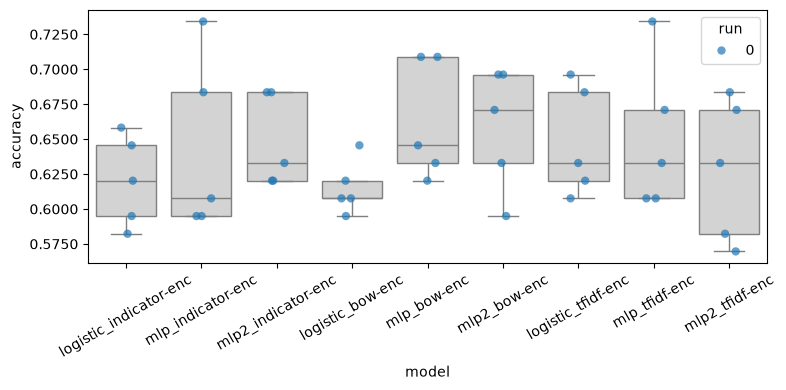

In [49]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [50]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.1779
P(Tie)    = 0.1746
P(B wins) = 0.6475
Effect Size = 0.72

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.0545
P(Tie)    = 0.1391
P(B wins) = 0.8064
Effect Size = 1.51

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.2668
P(Tie)    = 0.3159
P(B wins) = 0.4172
Effect Size = 0.23


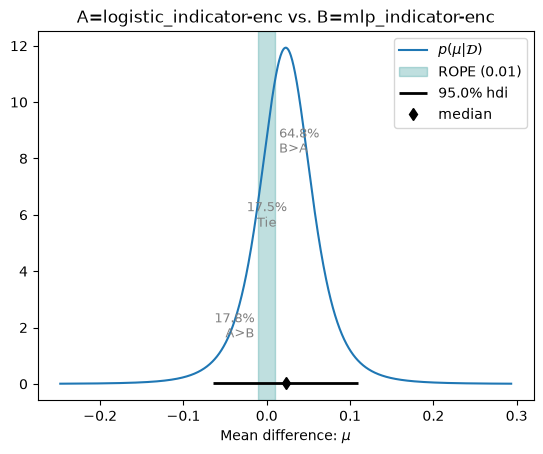

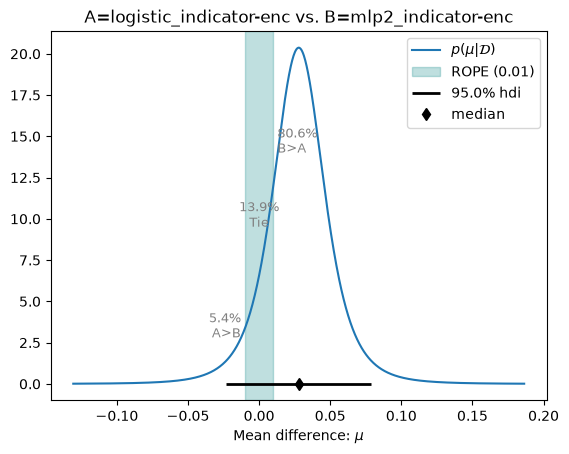

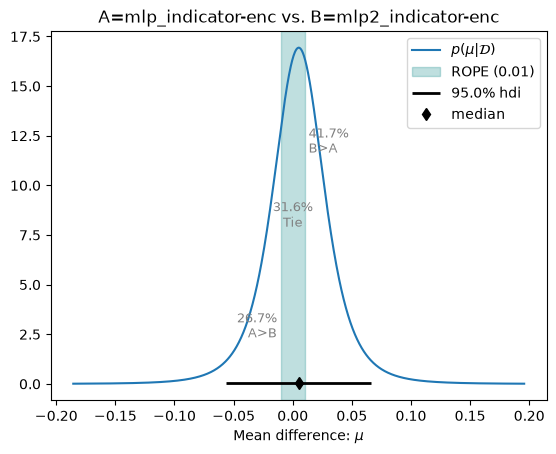

In [51]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.01

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [52]:
results = []

for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)
print(df.round(4))

                  Model A             Model B  P(A wins)  P(Tie)  P(B wins)  \
0  logistic_indicator-enc   mlp_indicator-enc     0.2133  0.0876     0.6991   
1  logistic_indicator-enc  mlp2_indicator-enc     0.0745  0.0667     0.8588   
2       mlp_indicator-enc  mlp2_indicator-enc     0.3365  0.1624     0.5011   

   Effect Size  
0       0.7249  
1       1.5128  
2       0.2287  


In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for sys_name, runs in classifiers.items():
    acc, prec, rec, f1 = [], [], [], []
    for r, run_data in enumerate(runs):
        for i, (fold, preds) in enumerate(run_data['predictions'].items()):
            gold = [y for _, y in my_cross_validation_sets[r][i]["validation"]]
            acc.append(accuracy_score(gold, preds))
            prec.append(precision_score(gold, preds, average="macro", zero_division=0))
            rec.append(recall_score(gold, preds, average="macro", zero_division=0))
            f1.append(f1_score(gold, preds, average="macro", zero_division=0))
    rows.append({
        "model": sys_name,
        "accuracy": np.mean(acc),
        "precision": np.mean(prec),
        "recall": np.mean(rec),
        "f1": np.mean(f1),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

                 model  accuracy  precision  recall     f1
logistic_indicator-enc    0.6203     0.5837  0.5053 0.5178
     mlp_indicator-enc    0.6430     0.4733  0.4730 0.4618
    mlp2_indicator-enc    0.6481     0.4745  0.4829 0.4742
      logistic_bow-enc    0.6152     0.5776  0.4848 0.4966
           mlp_bow-enc    0.6633     0.4859  0.4932 0.4840
          mlp2_bow-enc    0.6582     0.4856  0.4832 0.4735
    logistic_tfidf-enc    0.6481     0.5038  0.4687 0.4527
         mlp_tfidf-enc    0.6506     0.4762  0.4813 0.4716
        mlp2_tfidf-enc    0.6278     0.4561  0.4648 0.4545
